In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import os

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


1. **df_raw** são os dados puros, sem balançeamento dos dados e normalização da coluna mortos

2. **df_balanced** são os dados com a coluna mortos transormada em booleana e balançeados em 50% dados fatais e 50% dados não fatais

In [ ]:
df_raw = pd.read_parquet('/content/drive/MyDrive/Machine Learning/data/prf_puro.parquet')
df_balanced = pd.read_parquet('/content/drive/MyDrive/Machine Learning/data/prf_balanceado.parquet')

df_raw.head()

,dia_semana,uf,br,causa_acidente,tipo_acidente,fase_dia,condicao_metereologica,tipo_pista,tracado_via,uso_solo,pessoas,mortos,veiculos
0,segunda-feira,TO,153,Falta de Atenção à Condução,Colisão frontal,Pleno dia,Céu Claro,Simples,Aclive,Não,2,0,2
1,segunda-feira,SE,101,Não guardar distância de segurança,Colisão traseira,Pleno dia,Céu Claro,Dupla,Reta,Não,2,0,2
2,segunda-feira,TO,153,Falta de Atenção à Condução,Colisão lateral,Pleno dia,Céu Claro,Simples,Reta;Interseção de Vias,Não,3,0,3
3,segunda-feira,PA,155,Ingestão de Álcool,Colisão lateral,Amanhecer,Céu Claro,Simples,Reta,Não,2,1,2
4,segunda-feira,BA,116,Ultrapassagem Indevida,Saída de leito carroçável,Pleno dia,Sol,Simples,Reta,Não,2,0,2


### Dicionário de Dados – Dataset PRF

Abaixo estão descrições das principais colunas do dataset de "Acidentes da PRF".

| Coluna         | Descrição |
|----------------|----------|
| `dia_semana`     | Indica o dia da semana(**Segunda-Feira**, **Terca-Feira**, **Etc.**). |
| `uf`       | A unidade federativa onde ocorreu o acidente(**MG**, **PE**, **DF**, **ETC**).|
| `br`          | Código da rodovia federal onde ocorreu o acidente.  |
| `causa_acidente`          | Motivo principal do acidente. |
| `tipo_acidente`        | Classificação do acidente ocorrido. |
| `fase_dia`        | Período do dia em que ocorreu o acidente. |
| `condicao_metereologico`         | Condições climáticas no momento do acidente.|
| `tipo_pista`     | Tipo de pista da rodovia. |
| `tracado_via`        | Geometria da via no local do acidente. |
| `uso_solo`          | Tipo de ocupação da área ao redor da via(Urbano=Sim; Rural=Não). |
| `pessoas`   | Número total de pessoas envolvidas no acidente. |
| `mortos`         | Número de vítimas fatais no acidente. |
| `veiculos`        | Quantidade de veículos envolvidos no acidente |


---


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 543100 entries, 0 to 543099
Data columns (total 13 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   dia_semana              543100 non-null  object
 1   uf                      543100 non-null  object
 2   br                      543100 non-null  int64 
 3   causa_acidente          543100 non-null  object
 4   tipo_acidente           543059 non-null  object
 5   fase_dia                543100 non-null  object
 6   condicao_metereologica  543100 non-null  object
 7   tipo_pista              543100 non-null  object
 8   tracado_via             543100 non-null  object
 9   uso_solo                543100 non-null  object
 10  pessoas                 543100 non-null  int64 
 11  mortos                  543100 non-null  int64 
 12  veiculos                543100 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 53.9+ MB


In [ ]:
df_raw.describe()

,br,pessoas,mortos,veiculos
count,543100.000000,543100.000000,543100.000000,543100.000000
mean,211.403955,2.550976,0.082073,1.972701
std,130.416310,2.082086,0.338756,1.095341
min,0.000000,1.000000,0.000000,1.000000
25%,101.000000,2.000000,0.000000,1.000000
50%,158.000000,2.000000,0.000000,2.000000
75%,324.000000,3.000000,0.000000,2.000000
max,498.000000,95.000000,37.000000,131.000000


In [ ]:
print(df_raw['veiculos'].dtype)
print(df_raw['veiculos'].head(10))

int64
0    2
1    2
2    3
3    2
4    2
5    3
6    4
7    4
8    6
9    2
Name: veiculos, dtype: int64


# Análise dos valores da classe

A coluna mortos (classe) possui valores entre 0 a 37, a partir da análise do gráfico abaixo, podemos concluir que apenas os valores **0** e **1** se repetem constantemente, tornando os outros valores pouco relevantes.

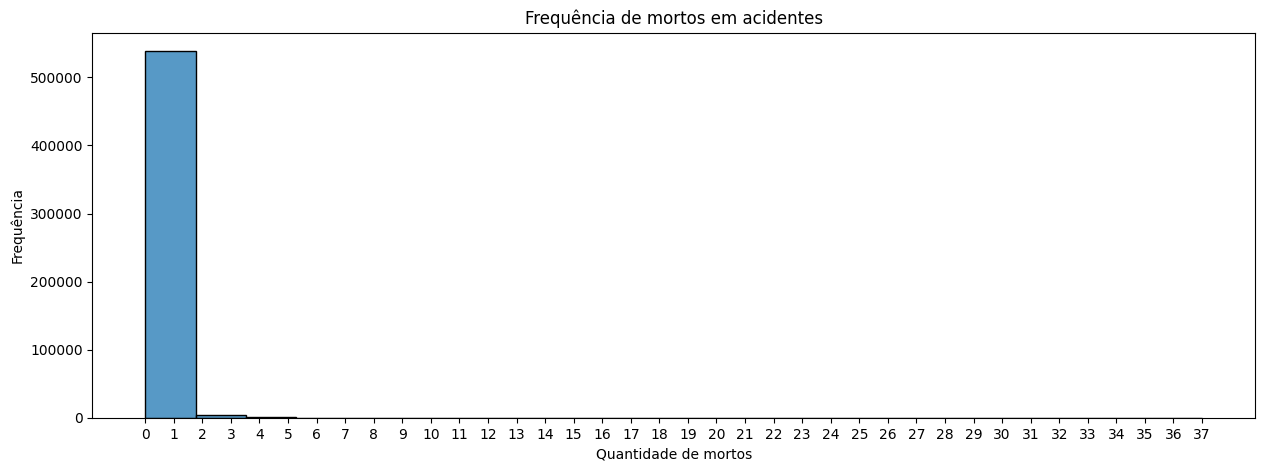

In [ ]:
plt.figure(figsize=(15, 5))
sns.histplot(df_raw['mortos'].dropna())
plt.title('Frequência de mortos em acidentes')
plt.xlabel('Quantidade de mortos')
plt.ylabel('Frequência')
plt.xticks(range(0, int(df_raw['mortos'].max()) + 1))
plt.show()

Para uma visualização melhor e exata dos dados:

In [ ]:
print(f'\nTotal: {len(df_raw)} linhas')
print(df_raw['mortos'].value_counts())


Total: 543100 linhas
mortos
0     504849
1      33853
2       3280
3        698
4        257
5         98
6         29
7         15
8          5
9          3
12         3
11         2
13         2
19         1
23         1
14         1
37         1
16         1
10         1
Name: count, dtype: int64


# Transformando a classe em binária

A partir disso, tomamos a decisão de considerar apenas os valores **0** (acidentes sem mortos) e **1** (acidentes com 1 ou mais mortos).

A linha abaixo normaliza a coluna de mortos, ao invés de valores que variam de 0 a 37, ele transforma os dados em **0** e **1**.

In [ ]:
df_raw['mortos'] = (df_raw['mortos'] >= 1).astype(int)

Isso torna a visualização dos dados melhor e desconsidera os valores que se repetiam poucas vezes.

Com apenas dois válores possíveis, o modelo de aprendizado que será usado no futuro será de **Classificação Binária**.

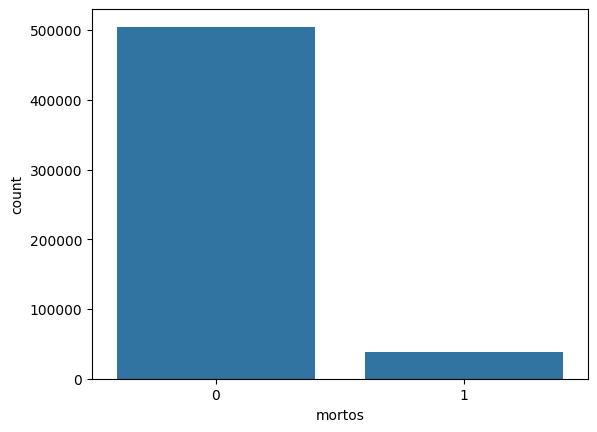

In [ ]:
sns.countplot(x = df_raw['mortos']);

Para uma visualização melhor e exata dos dados:

In [ ]:
counts = df_raw['mortos'].value_counts()
percent = df_raw['mortos'].value_counts(normalize=True) * 100

resultado = pd.DataFrame({
    'Quantidade': counts,
    'Porcentagem': percent.round(2)
})

print(resultado)

        Quantidade  Porcentagem
mortos                         
0           504849        92.96
1            38251         7.04


# Balanceamento

Os dados já foram padronizados, o que ajuda muito a visualização deles e partir dessa visualização, pode-se perceber que a base de dados está muito desbalanceada, possuindo apenas cerca de 7% dos dados com a classe igual 1, o que pode dificultar muito o aprendizado futuro.

Com isso em mente, foi gerado um algoritmo no qual ao invés de juntar os dados de 2018 a 2025 deliberadamente, ele intera por cada ano com o seguinte comportamento:


*   Busca os arquivos de cada ano no drive (necessário ser armazenado previamente).
*   Normaliza a coluna mortos para os valores 0 e 1.
*   Busca e armazena todas as amostras com o valor da classe igual a 1.
*   Busca aleatóriamente a mesma quantidade de amostras com a classe igual 0 (O algoritmo usa uma seed pré-definida, fazendo com que mesmo que busque aleatóriamente, a cada execução ele irá gerar o mesmo resultado).

Isso é feito em looping até ler todos os arquivos e juntar todas as amostras no final, gerando uma base de dados completamente balanceados.


In [ ]:
df_balanced.head()

,dia_semana,uf,br,causa_acidente,tipo_acidente,fase_dia,condicao_metereologica,tipo_pista,tracado_via,uso_solo,pessoas,mortos,veiculos
0,terça-feira,PE,232,Condutor Dormindo,Saída de leito carroçável,Plena Noite,Céu Claro,Dupla,Reta,Não,1,0,1
1,sexta-feira,SP,381,Ausência de reação do condutor,Colisão traseira,Pleno dia,Céu Claro,Simples,Reta,Sim,2,0,2
2,quinta-feira,RS,470,Reação tardia ou ineficiente do condutor,Colisão traseira,Pleno dia,Nevoeiro/Neblina,Simples,Reta,Não,2,0,2
3,quinta-feira,RS,392,Velocidade Incompatível,Colisão frontal,Plena Noite,Céu Claro,Simples,Ponte,Não,3,1,6
4,segunda-feira,PR,116,Ausência de reação do condutor,Colisão com objeto,Amanhecer,Garoa/Chuvisco,Simples,Declive,Não,53,1,1


In [ ]:
df_balanced.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76502 entries, 0 to 76501
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   dia_semana              76502 non-null  object
 1   uf                      76502 non-null  object
 2   br                      76502 non-null  int64 
 3   causa_acidente          76502 non-null  object
 4   tipo_acidente           76496 non-null  object
 5   fase_dia                76502 non-null  object
 6   condicao_metereologica  76502 non-null  object
 7   tipo_pista              76502 non-null  object
 8   tracado_via             76502 non-null  object
 9   uso_solo                76502 non-null  object
 10  pessoas                 76502 non-null  int64 
 11  mortos                  76502 non-null  int64 
 12  veiculos                76502 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 7.6+ MB


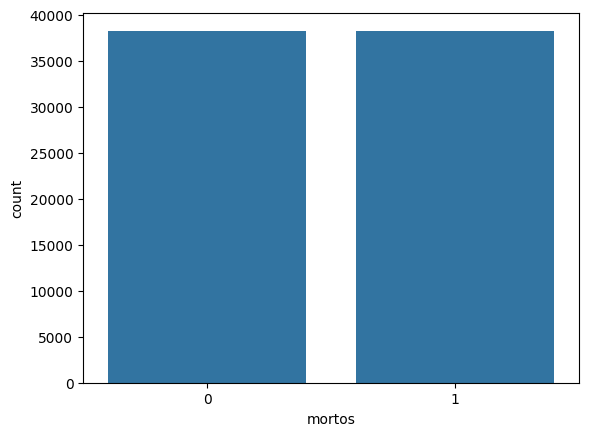

In [ ]:
sns.countplot(x = df_balanced['mortos']);

# Verificação e tratamento de dados nulos

É importante que os dados nulos sejam tratados para não prejudicar o futuro aprendizado.

In [ ]:
print("--- Dados nulos ANTES do tratamento ---")
df_balanced.isnull().sum()

--- Dados nulos ANTES do tratamento ---


,0
dia_semana,0
uf,0
br,0
causa_acidente,0
tipo_acidente,6
fase_dia,0
condicao_metereologica,0
tipo_pista,0
tracado_via,0
uso_solo,0


In [ ]:
df_balanced.loc[pd.isnull(df_balanced['tipo_acidente'])]

,dia_semana,uf,br,causa_acidente,tipo_acidente,fase_dia,condicao_metereologica,tipo_pista,tracado_via,uso_solo,pessoas,mortos,veiculos
5693,sábado,BA,116,Falta de Atenção à Condução,None,Plena Noite,Céu Claro,Simples,Reta,Não,2,1,2
9387,sábado,MA,135,Falta de Atenção à Condução,None,Pleno dia,Céu Claro,Simples,Aclive;Curva,Não,4,1,1
30596,segunda-feira,BA,235,Falta de Atenção à Condução,None,Pleno dia,Ignorado,Simples,Reta,Sim,2,0,2
42283,domingo,PR,487,Ingestão de Álcool,None,Plena Noite,Céu Claro,Simples,Aclive,Não,2,0,1
55266,sexta-feira,SC,280,Ultrapassagem Indevida,None,Plena Noite,Céu Claro,Simples,Declive,Sim,3,1,2
61792,quarta-feira,MG,381,Falta de Atenção à Condução,None,Pleno dia,Céu Claro,Simples,Reta,Sim,1,0,1


Como são apenas 6 amostras de uma base com cerca de 76.000 e a coluna `tipo_acidente` não é númerica com valores dificeis de prever o melhor é apenas apagar essas amostras.

Por sorte os valores estão igualmente distruibidos em relação a classe, contendo 3 com a classe 0 e 3 com a classe 1, fazendo com que a remoção não quebre o balanceamento dos dados.

In [ ]:
# Removendo as 6 linhas vazias da coluna 'tipo_acidente'
df_balanced = df_balanced.dropna(subset=['tipo_acidente'])

print("\n--- Dados nulos DEPOIS do tratamento ---")
df_balanced.isnull().sum()


--- Dados nulos DEPOIS do tratamento ---


,0
dia_semana,0
uf,0
br,0
causa_acidente,0
tipo_acidente,0
fase_dia,0
condicao_metereologica,0
tipo_pista,0
tracado_via,0
uso_solo,0


# Análise de Correlação (Heatmap)
Nesta etapa, analisamos a correlação matemática entre as variáveis numéricas do nosso dataset ('pessoas' e 'veiculos') em relação à nossa variável alvo ('mortos'). A coluna 'br' foi propositalmente excluída desta visualização por representar o número de identificação da rodovia (um dado categórico nominal), o que não faria sentido em um cálculo matemático de correlação. O objetivo é identificar se a quantidade de veículos ou de pessoas envolvidas possui forte relação com a fatalidade do acidente.

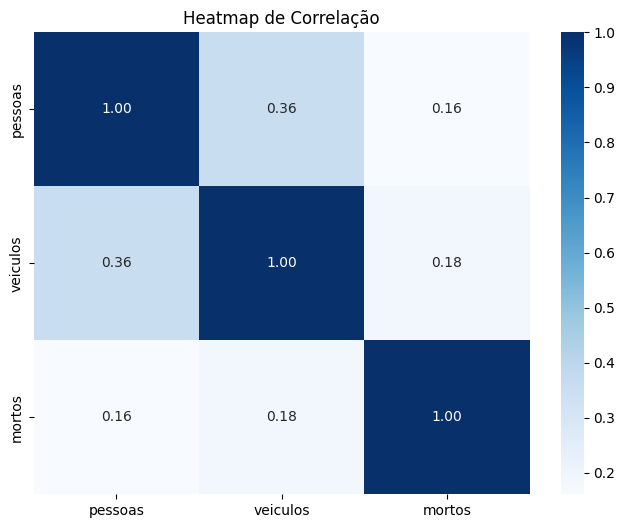

In [ ]:
colunas_numericas = ['pessoas', 'veiculos', 'mortos']

plt.figure(figsize=(8, 6))
sns.heatmap(df_balanced[colunas_numericas].corr(), annot=True, cmap='Blues', fmt=".2f")
plt.title('Heatmap de Correlação')
plt.show()

# Análise de Distribuição (Boxplot)

O gráfico abaixo analisa a quantidade de pessoas envolvidas comparando acidentes não fatais (0) e fatais (1). Limitamos o eixo Y para 10 pessoas para facilitar a visualização, ignorando os outliers, já que iremos gerar um gráfico mais para frente para uma melhor visualização deles.



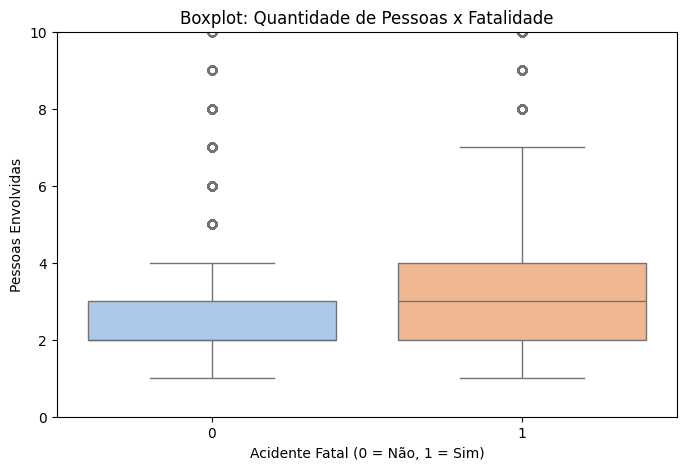

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='mortos', y='pessoas', data=df_balanced, palette='pastel', hue='mortos', legend=False)

plt.ylim(0, 10)

plt.title('Boxplot: Quantidade de Pessoas x Fatalidade')
plt.xlabel('Acidente Fatal (0 = Não, 1 = Sim)')
plt.ylabel('Pessoas Envolvidas')
plt.show()

*Boxplot de Pessoas x Fatalidade (versão ampliada).*

# Análise de Distribuição por Categoria (Countplot)

Com este gráfico, buscamos entender se o período do dia influencia na letalidade dos acidentes, observando a proporção de acidentes fatais e não fatais em cada fase.

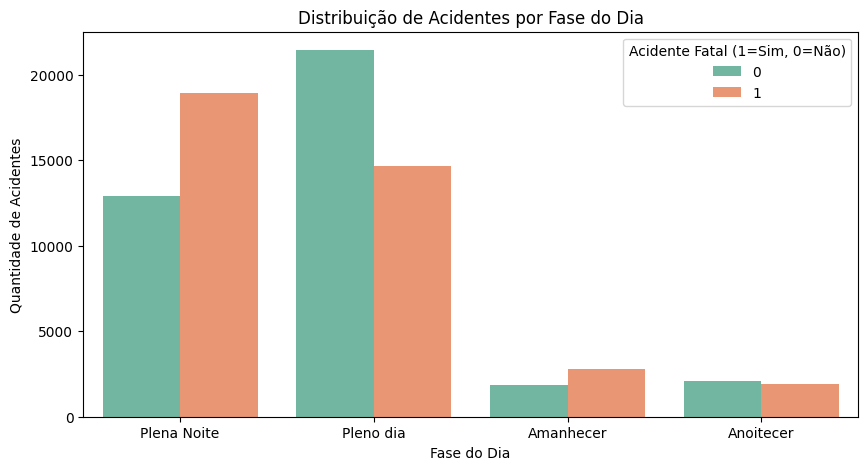

In [ ]:

plt.figure(figsize=(10, 5))
# Gráfico de barras contando acidentes por fase do dia, divididos pela fatalidade
sns.countplot(x='fase_dia', hue='mortos', data=df_balanced, palette='Set2')

plt.title('Distribuição de Acidentes por Fase do Dia')
plt.xlabel('Fase do Dia')
plt.ylabel('Quantidade de Acidentes')
plt.legend(title='Acidente Fatal (1=Sim, 0=Não)')
plt.show()

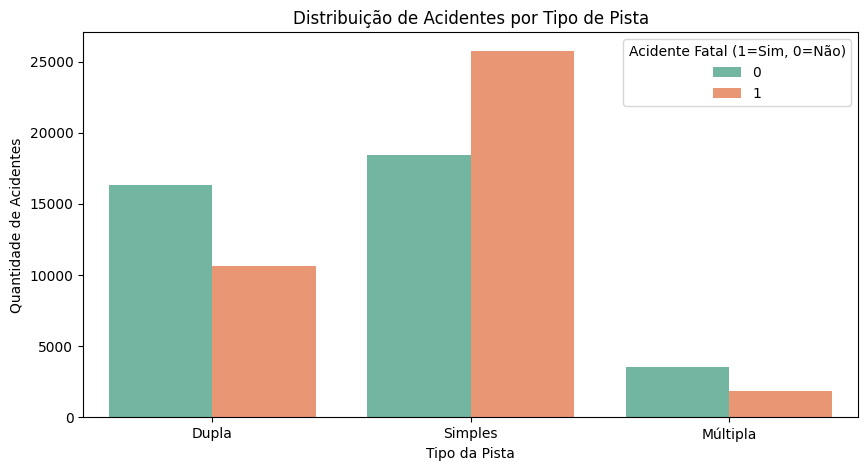

In [ ]:

plt.figure(figsize=(10, 5))
# Gráfico de barras contando acidentes por tipo de pista, divididos pela fatalidade
sns.countplot(x='tipo_pista', hue='mortos', data=df_balanced, palette='Set2')

plt.title('Distribuição de Acidentes por Tipo de Pista')
plt.xlabel('Tipo da Pista')
plt.ylabel('Quantidade de Acidentes')
plt.legend(title='Acidente Fatal (1=Sim, 0=Não)')
plt.show()

# Gráfico para melhor visualização dos dados númericos e identificação de outliers (Scatter Matrix)

O gráfico interativo abaixo relaciona todas a colunas númericas, ajudando a visualizar a relação entre elas e a identificar outliers.

In [ ]:
grafico = px.scatter_matrix(df_balanced[['pessoas', 'veiculos', 'mortos']], color= 'mortos')
grafico.show()

# Tratamento dos Outliers

A partir da análise do gráfico acima, podemos perceber alguns outliers principalmente nas colunas `pessoas` e `veiculos`, porém não vamos nos prender apenas na parte visual, vamos fazer verificações mais rigidas de outliers.

## Tratamento dos Outliers - Pessoas

Vamos começar visualizando alguns valores com o `.describe()`.

In [ ]:
df_balanced['pessoas'].describe()

,pessoas
count,76496.000000
mean,2.981973
std,3.046757
min,1.000000
25%,2.000000
50%,2.000000
75%,3.000000
max,95.000000


Podemos perceber que é um salto enorme entre os 75% e o valor máximo, esse é um ponto que precisa de muita atenção, por isso iremos usar o .`quantile()` para visualizar as seguintes porcentagens:


*   0.95 (95%) → 95% dos valores são menores ou iguais a esse número.
*   0.99 (99%) → 99% dos valores são menores ou iguais.
*   0.999 (99.9%) → 99.9% dos valores são menores ou iguais



In [ ]:
df_balanced['pessoas'].quantile([0.95, 0.99, 0.999])

,pessoas
0.950,6.0
0.990,11.0
0.999,48.0


Mediante aos dados apresentados, podemos constatar o seguinte:
*   95% dos valores são menores que 6.
*   Há um salto muito grande entre 75% e o máximo.

A partir disso podemos aplicar a regra do `IQR` da seguinte forma:

  `IQR = Q3 - Q1 `

Onde Q3 = 75% dos valores dos dados e Q1 é igual a 25%.

`IQR = 3 - 2 = 1`

Valores que estão abaixo de `Q1 - 1,5 * IQR` ou acima de `Q3 + 1,5 * IQR` geralmente são considerados outliers, ou seja, valores acima de 5 (arredondando para cima 3 + 1.5 * 1) são outliers.

Vamos vizualizar como ficariam os dados sem outliers.

In [ ]:
df_balanced[df_balanced['pessoas'] <= 5]['pessoas'].describe()

,pessoas
count,71050.000000
mean,2.488684
std,1.102493
min,1.000000
25%,2.000000
50%,2.000000
75%,3.000000
max,5.000000


In [ ]:
df_balanced.loc[df_balanced['pessoas'] > 5]

,dia_semana,uf,br,causa_acidente,tipo_acidente,fase_dia,condicao_metereologica,tipo_pista,tracado_via,uso_solo,pessoas,mortos,veiculos
4,segunda-feira,PR,116,Ausência de reação do condutor,Colisão com objeto,Amanhecer,Garoa/Chuvisco,Simples,Declive,Não,53,1,1
5,terça-feira,MT,163,Transitar na contramão,Colisão frontal,Pleno dia,Nublado,Simples,Reta;Em Obras,Não,7,1,7
58,domingo,SC,282,Velocidade Incompatível,Colisão transversal,Anoitecer,Chuva,Simples,Curva,Não,8,1,3
66,sexta-feira,BA,116,Ultrapassagem Indevida,Colisão frontal,Pleno dia,Ignorado,Simples,Reta,Não,7,1,5
96,sexta-feira,SC,116,Ausência de reação do condutor,Colisão com objeto,Plena Noite,Céu Claro,Simples,Rotatória,Não,8,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
76459,segunda-feira,PR,373,Desobediência às normas de trânsito pelo condutor,Colisão transversal,Pleno dia,Sol,Dupla,Interseção de Vias,Não,8,0,2
76481,terça-feira,RJ,116,Falta de Atenção à Condução,Colisão traseira,Pleno dia,Chuva,Dupla,Reta,Não,8,0,4
76483,domingo,SE,101,Ultrapassagem Indevida,Colisão frontal,Pleno dia,Sol,Simples,Aclive,Sim,8,1,10
76490,sexta-feira,RS,285,Falta de Atenção à Condução,Colisão lateral,Pleno dia,Céu Claro,Simples,Reta,Não,10,1,6


Seriam removidos 5400 amostras, o que não é tanto assim considerando que temos 76502 amostras.

Claro que quanto mais melhor, mas nesse caso além da regra do IQR, as amostras com mais de 5 pessoas muito provavelmente seriam de ônibus, vans, etc e queremos nos manter em apenas acidentes de carros e motos, por isso vamos aplicar essa mudança.

In [ ]:
df_clean = df_balanced[df_balanced['pessoas'] <= 5]
print(f"Removidos: {len(df_balanced) - len(df_clean)} amostras")

Removidos: 5446 amostras


## Tratamento de Outliers - Veiculos

Vamos manter a mesma estrutura, primeiro analisando o `.describe()` e o `.quantile()`

In [ ]:
df_clean['veiculos'].describe()

,veiculos
count,71050.000000
mean,2.080591
std,1.072054
min,1.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,38.000000


In [ ]:
df_clean['veiculos'].quantile([0.95, 0.99, 0.999])

,veiculos
0.950,4.0
0.990,6.0
0.999,10.0


Aplicando a regra do IQR:

`IQR = 2 - 1 = 1`

Limite superior = `3 + 1.5 * 1 ~= 5`

Limite inferior = `1 - 1.5 * 1 ~= 1`

Vamos verificar os outliers em **veiculos**.

In [ ]:
df_clean[df_clean['veiculos'] <= 5]['veiculos'].describe()

,veiculos
count,70290.000000
mean,2.024897
std,0.902922
min,1.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,5.000000


In [ ]:
df_clean.loc[df_balanced['veiculos'] > 5]

,dia_semana,uf,br,causa_acidente,tipo_acidente,fase_dia,condicao_metereologica,tipo_pista,tracado_via,uso_solo,pessoas,mortos,veiculos
3,quinta-feira,RS,392,Velocidade Incompatível,Colisão frontal,Plena Noite,Céu Claro,Simples,Ponte,Não,3,1,6
196,sexta-feira,RO,364,Ultrapassagem Indevida,Colisão lateral sentido oposto,Pleno dia,Sol,Simples,Curva,Não,4,1,11
218,sábado,SP,116,Velocidade Incompatível,Colisão lateral mesmo sentido,Pleno dia,Garoa/Chuvisco,Simples,Curva,Não,4,1,6
229,sábado,PR,277,Problema com o freio,Colisão lateral mesmo sentido,Plena Noite,Céu Claro,Simples,Curva,Não,4,0,6
233,sábado,RO,364,Reação tardia ou ineficiente do condutor,Colisão traseira,Pleno dia,Céu Claro,Simples,Declive,Não,4,1,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
75867,quarta-feira,GO,40,Retorno proibido,Colisão transversal,Plena Noite,Céu Claro,Simples,Curva,Não,5,1,6
76030,sexta-feira,MT,70,Ausência de reação do condutor,Colisão traseira,Pleno dia,Céu Claro,Simples,Reta,Não,4,0,7
76137,sexta-feira,MT,163,Ultrapassagem Indevida,Colisão frontal,Pleno dia,Chuva,Simples,Curva,Não,5,1,7
76222,sexta-feira,MG,262,Velocidade Incompatível,Colisão frontal,Pleno dia,Chuva,Simples,Curva,Não,3,1,15


In [ ]:
before = df_clean
df_clean = df_clean[df_clean['veiculos'] <= 5]
print(f"Removidos: {len(before) - len(df_clean)} amostras")

Removidos: 760 amostras


Serião removidos 760 amostras, apenas aproximadamente 1% dos dados.

Vamos aplicar essa mudança.

# Visualização dos dados tratados

Agora que tratamos os dados, vamos visualizar gráficamente como ficou

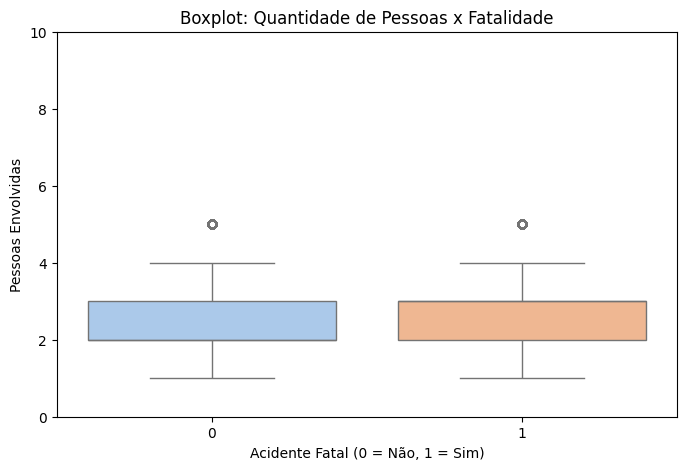

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='mortos', y='pessoas', data=df_clean, palette='pastel', hue='mortos', legend=False)

plt.ylim(0, 10)

plt.title('Boxplot: Quantidade de Pessoas x Fatalidade')
plt.xlabel('Acidente Fatal (0 = Não, 1 = Sim)')
plt.ylabel('Pessoas Envolvidas')
plt.show()

In [ ]:
grafico = px.scatter_matrix(df_clean[['pessoas', 'veiculos', 'mortos']], color= 'mortos')
grafico.show()

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 70290 entries, 0 to 76501
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   dia_semana              70290 non-null  object
 1   uf                      70290 non-null  object
 2   br                      70290 non-null  int64 
 3   causa_acidente          70290 non-null  object
 4   tipo_acidente           70290 non-null  object
 5   fase_dia                70290 non-null  object
 6   condicao_metereologica  70290 non-null  object
 7   tipo_pista              70290 non-null  object
 8   tracado_via             70290 non-null  object
 9   uso_solo                70290 non-null  object
 10  pessoas                 70290 non-null  int64 
 11  mortos                  70290 non-null  int64 
 12  veiculos                70290 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 9.5+ MB


In [ ]:
pasta = '/content/drive/MyDrive/Machine Learning/data/'

saida = os.path.join(pasta, 'prf_clean.parquet')
df_clean.to_parquet(saida, index=False)
print(f'\n💾 Salvo em: {saida}')


💾 Salvo em: /content/drive/MyDrive/Machine Learning/data/prf_clean.parquet
